## SANOS one Fit

Notebook to fit SANOS to one expiry abd display the fit for all expiries.



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Linear only

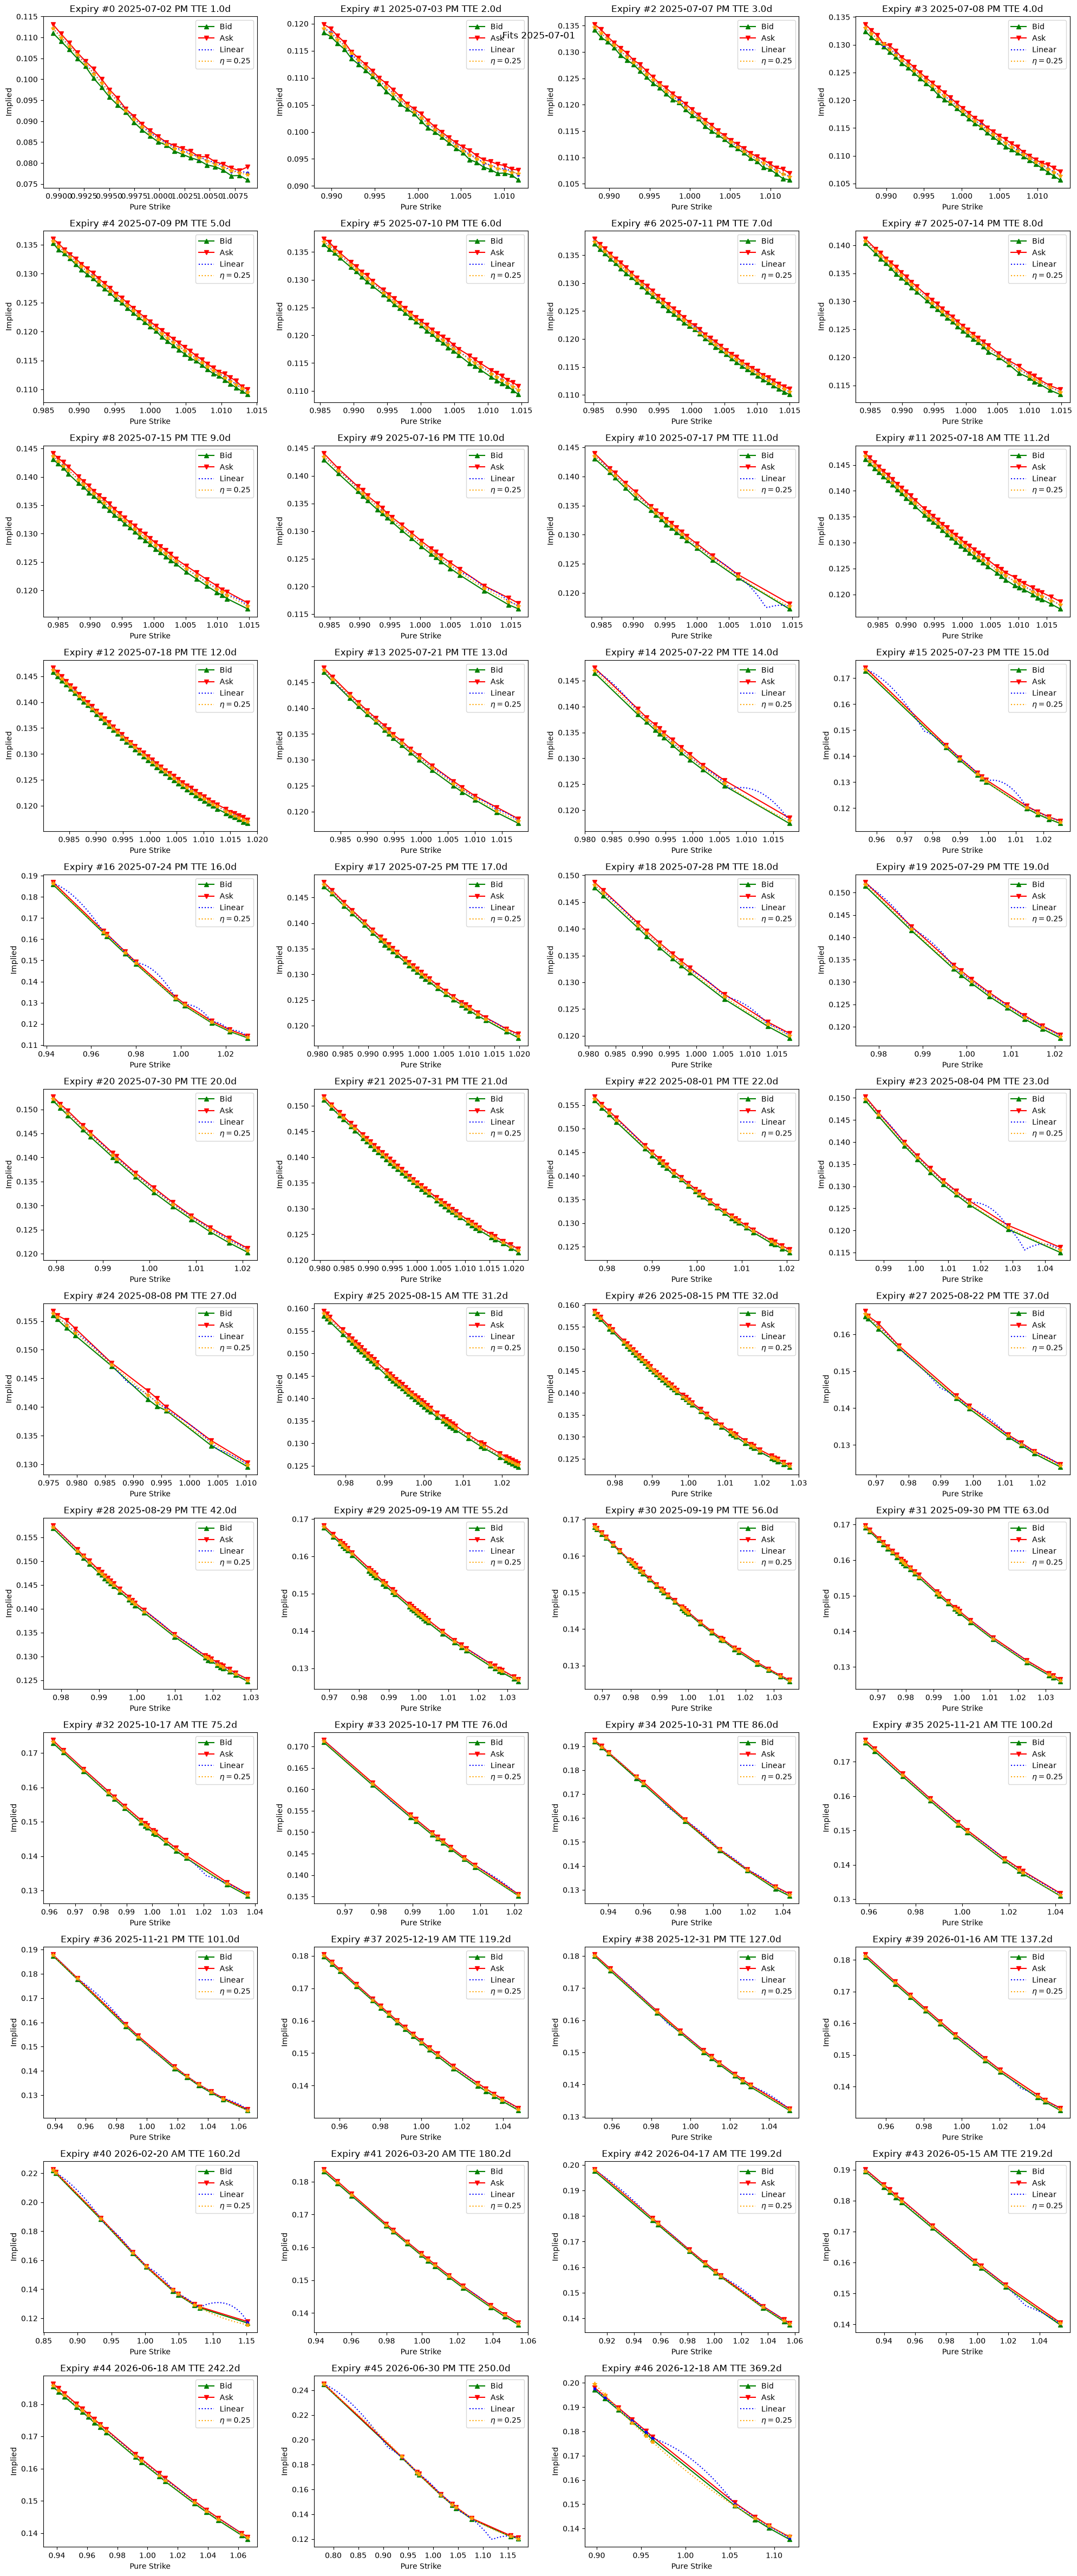

00: Surface 2025-07-01 expiry #0 1.0d: Generating extended strikes... using 27 extended strikes based on 25 market strikes.
00: Surface 2025-07-01 expiry #0 1.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 8.76ms.
00: Surface 2025-07-01 expiry #1 2.0d: Generating extended strikes... using 31 extended strikes based on 29 market strikes.
00: Surface 2025-07-01 expiry #0 1.0d: Generating extended strikes... using 27 extended strikes based on 25 market strikes.
00: Surface 2025-07-01 expiry #0 1.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 8.76ms.
00: Surface 2025-07-01 expiry #1 2.0d: Generating extended strikes... using 31 extended strikes based on 29 market strikes.
00: Surface 2025-07-01 expiry #1 2.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 0.031s.
00: Surface 2025-07-01 expiry #2 3.0d: Generating extended strikes... using 33 extended strikes based on 31 market strikes.
00: Surface

In [7]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.arbfree

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, store
from cdxcore.verbose import Context
from quantdata.biz_calendar import DAYS_PER_YEAR, to_date
from cdxcore.pretty import PrettyObject
import numpy as np
from IPython.display import Markdown, display

from quantdata.widb.options_filter import MkArbFree, RawDayFilter, ExpiryFilter, OptionsFilter, filter_options_day
from quantdata.biz_calendar import DAYS_PER_YEAR, to_date
def assess_fit(d, ticker = "SPX", do_smooth : bool = True):
    d = to_date(d)
    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    options_filter = OptionsFilter()

    data = filter_options_day(ticker,d, mk_arb_free=None, options_filter=options_filter, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=Context.all )

    strikes = data['pure_strike'].to_numpy()
    tte_y   = data['tte_y'].to_numpy()
    bid_vol = data['bid_vol'].to_numpy()
    ask_vol = data['ask_vol'].to_numpy()
    bid     = data['pure_bid_price'].to_numpy()
    ask     = data['pure_ask_price'].to_numpy()
    exdate  = data['expiry'].to_numpy()
    is_am   = data['is_am'].to_numpy()

    ixs     = np.argsort(strikes)
    strikes = strikes[ixs]
    tte_y   = tte_y[ixs]
    bid_vol = bid_vol[ixs]
    ask_vol = ask_vol[ixs]
    bid     = bid[ixs]
    ask     = ask[ixs]
    exdate  = exdate[ixs]
    is_am   = is_am[ixs]
    del ixs

    # split into per-expiry
    # ---------------------

    market = PrettyObject()

    market.expiries = []
    market.strikes  = []
    market.bids     = []
    market.asks     = []
    market.ask_vols = []
    market.bid_vols = []
    market.mask     = []
    market.expiry_str = []
    uttys        = np.unique(tte_y)

    for utty in uttys:
        mask = tte_y == utty
        afk = strikes[mask]
        assert np.all( np.diff(afk) > 0. ), f"Expected strikes to be strictly increasing for TTE {utty}, but found strikes {afk}"

        market.expiry_str.append(f"{to_date(exdate[mask][0])} {'AM' if is_am[mask][0] else 'PM'}")

        market.mask.append(mask)
        market.expiries.append( utty)
        market.strikes.append( strikes[mask] )
        market.bids.append( bid[mask] )
        market.asks.append( ask[mask] )
        market.ask_vols.append( ask_vol[mask] )
        market.bid_vols.append( bid_vol[mask] )
    market.expiries = np.array(market.expiries)

    with figure(f"Fits {d}", col_size=5, row_size=4, columns=4 ) as fig_fits:

        axs = []
        for t, (expiry, xstr) in enumerate(zip(market.expiries, market.expiry_str)):
            ax = fig_fits.add_subplot(f"Expiry #{t} {xstr} TTE {expiry*DAYS_PER_YEAR:.1f}d")
            axs.append(ax)
            ax.set_xlabel("Pure Strike")
            ax.set_ylabel("Implied")

            strikes_t = market.strikes[t]

            ax.plot(strikes_t, market.bid_vols[t], "^-", color="green", label="Bid")
            ax.plot(strikes_t, market.ask_vols[t], "v-", color="red", label="Ask")
            ax.legend()
        fig_fits.render()

        # Fit
        # ---

        lin_arb_free = MkArbFree( "surface", smoothness=None, mid_fit_weight=0.1 )
        afl = lin_arb_free(
                expiries       = market.expiries, 
                strikes        = market.strikes,
                bids           = market.bids,
                asks           = market.asks,
                message_context= lambda : f"Surface {d}",
                verbose        = Context.all )
        mk_arb_free = MkArbFree( "surface", smoothness=0.25, mid_fit_weight=0.1 )
        afx = mk_arb_free(
                expiries       = market.expiries, 
                strikes        = market.strikes,
                bids           = market.bids,
                asks           = market.asks,
                message_context= lambda : f"Surface {d}",
                verbose        = Context.all ) if do_smooth else None

        for t, expiry in enumerate(market.expiries):
            strikes_t = market.strikes[t]
            more_strikes = np.linspace(strikes_t[0], strikes_t[-1], 100)
            _, mlinX_vols = afl.price( expiry, more_strikes, and_vols=True, mode="surface" )
            _, mfitX_vols = afx.price( expiry, more_strikes, and_vols=True, mode="surface" ) if do_smooth else (None, None)

            ax = axs[t]
            ax.plot(more_strikes, mlinX_vols, ":", color="blue", label=rf"Linear")
            ax.plot(more_strikes, mfitX_vols, ":", color="orange", label=rf"$\eta={mk_arb_free.smoothness:.2f}$") if do_smooth else None

            if t in afl.input_index:
                mt     = afl.input_index[t]
                mask_t = afl.masks[mt]
                mask_t = mask_t if not mask_t is None else slice(None)
                _, mlinX_vols = afl.price( expiry, strikes_t[mask_t], and_vols=True, mode="surface" )
                ax.plot(strikes_t[mask_t], mlinX_vols, ".", color="blue") 

            if do_smooth:
                if t in afx.input_index:
                    mt     = afx.input_index[t]
                    mask_t = afx.masks[mt]
                    mask_t = mask_t if not mask_t is None else slice(None)
                    _, mfitX_vols = afx.price( expiry, strikes_t[mask_t], and_vols=True, mode="surface" )
                    ax.plot(strikes_t[mask_t], mfitX_vols, "*", color="orange")

            ax.legend(loc="upper right")

        fig_fits.render()
        return afx, afl, market

display(Markdown("## Linear only"))
d = to_date("2025-07-01")
afx, afl, market = assess_fit(d, do_smooth=True )
print("/done")


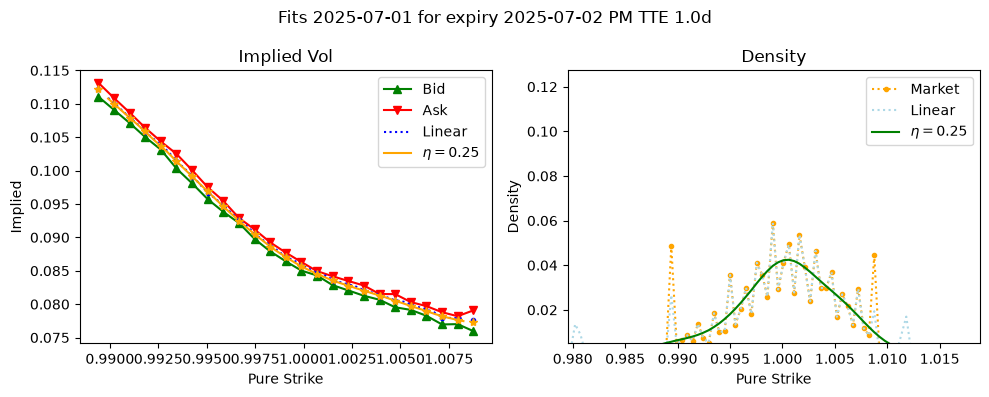

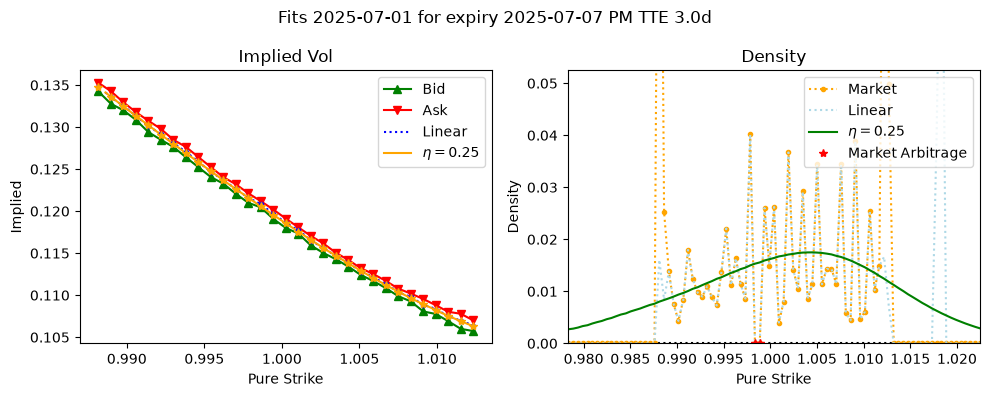

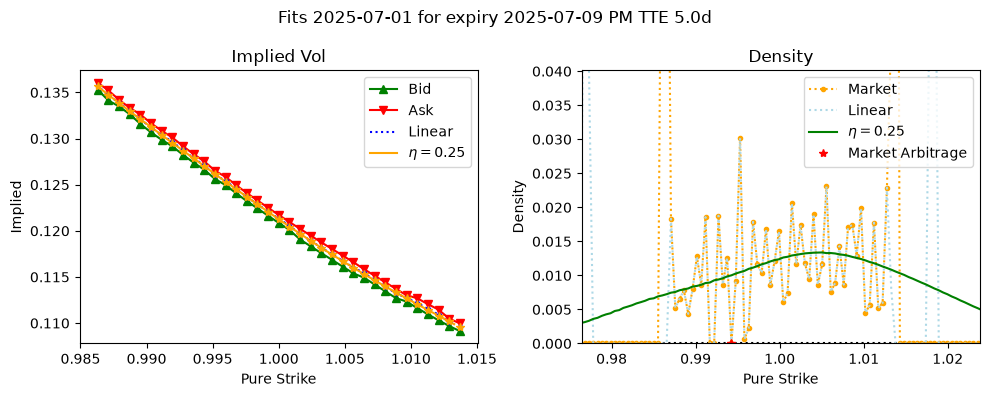

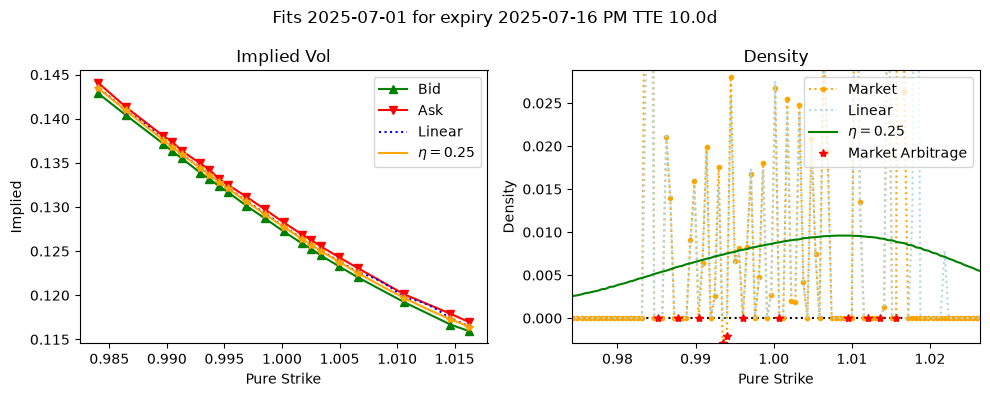

In [ ]:
def plot_single(afx, afl, market, d, show):

    for t in show:
        with figure(f"Fits {d} for expiry {market.expiry_str[t]} TTE {market.expiries[t]*DAYS_PER_YEAR:.1f}d", col_size=5, row_size=4, columns=4 ) as fig_fits:
            ax = fig_fits.add_subplot(f"Implied Vol")
            ax.set_xlabel("Pure Strike")
            ax.set_ylabel("Implied")

            strikes_t    = market.strikes[t]
            expiry       = market.expiries[t]
            ax.plot(strikes_t, market.bid_vols[t], "^-", color="green", label="Bid")
            ax.plot(strikes_t, market.ask_vols[t], "v-", color="red", label="Ask")

            more_strikes = np.linspace(strikes_t[0]*0.5, strikes_t[-1]*1.5, 2000)
            ext_market   = np.concatenate([[0], strikes_t, [strikes_t[-1]*2]])
            ext_calls    = np.concatenate([[1], 0.5*(market.bids[t]+market.asks[t]), [0.]])
            market_C     = np.interp( more_strikes, ext_market, ext_calls, left=1., right=0. )
            inner        = ( more_strikes >= strikes_t[0]) & (more_strikes <= strikes_t[-1])
            mlinX_C, mlinX_vols = afl.price( expiry, more_strikes, and_vols=True, mode="surface" )
            mfitX_C, mfitX_vols = afx.price( expiry, more_strikes, and_vols=True, mode="surface" ) 
            ax.plot(more_strikes[inner], mlinX_vols[inner], ":", color="blue", label=rf"Linear")
            ax.plot(more_strikes[inner], mfitX_vols[inner], "-", color="orange", label=rf"$\eta={afx.smoothness:.2f}$") 

            mask_t      = afl.masks[t]
            mask_t      = mask_t if not mask_t is None else slice(None)
            mstrikes_t  = market.strikes[t][mask_t]

            _, mlin_vols = afl.price( expiry, mstrikes_t, and_vols=True, mode="surface" )
            _, mfit_vols = afx.price( expiry, mstrikes_t, and_vols=True, mode="surface" )
            ax.plot(mstrikes_t, mlin_vols, ".", color="lightblue") 
            ax.plot(mstrikes_t, mfit_vols, "*", color="orange")
            ax.legend(loc="upper right")

            # density
            ax = fig_fits.add_subplot(f"Density")
            ax.set_xlabel("Pure Strike")
            ax.set_ylabel("Density")

            def p( calls ):
                return np.diff( np.diff(calls, prepend=1.) / np.diff(more_strikes,prepend=0.), append=0. )

            market_p = p(market_C)
            lin_p    = p(mlinX_C)
            fit_p    = p(mfitX_C)

            ax.plot(more_strikes, more_strikes*0., ":", color="black")
            ax.plot(more_strikes, market_p, ".:", color="orange", label=rf"Market")
            ax.plot(more_strikes, lin_p, ":", color="lightblue", label=rf"Linear")
            ax.plot(more_strikes, fit_p, "-", color="orange", label=rf"$\eta={afx.smoothness:.2f}$")
            ax.set_xlim(strikes_t[0]*0.99, strikes_t[-1]*1.01)
            ax.set_ylim(np.min(market_p[inner]),np.max(fit_p[inner])*3.)
            neg = market_p[inner]<0
            if np.any(neg):
                ax.plot(more_strikes[inner][neg], market_p[inner][neg], "*", color="red", label=rf"Market Arbitrage")
            ax.legend(loc="upper right")

            fig_fits.close()

plot_single(afx, afl, market, d, show=[0,2,4,9])